# 02 — Preprocessing & Chunking (Structure-Aware)

**Tujuan:** menyiapkan basis pengetahuan: memecah teks interim tiap dokumen menjadi
chunk siap-index, dengan strategi *structure-aware* (§6 `perancangan.md`).

Heading `BAB` adalah batas KERAS (selalu memulai chunk baru); heading lain (`A.`,
`2.1.`, dst) adalah batas LUNAK — hanya mengisi metadata `section_heading`, tidak
memaksa pemotongan, supaya sub-bagian pendek tidak pecah jadi chunk-chunk kecil.
Paragraf yang lebih panjang dari `chunk_size` dipecah lebih lanjut lewat kaskade
paragraf → kalimat → kata → karakter, dengan overlap adaptif antar-chunk sehingga
`chunk_size` tidak pernah dilanggar (lihat `src/chunking.py` untuk detail algoritma).

**INPUT:** `../data/processed/documents.jsonl`, `../data/interim/{doc_id}.txt`

**OUTPUT:** `../data/processed/chunks.jsonl`

**Perkiraan runtime:** < 1 menit untuk korpus saat ini

**Perkiraan biaya API:** Rp 0 — tidak ada panggilan LLM di notebook ini

**Assert di notebook ini:** `chunk_id` unik lintas seluruh dokumen; `page_start <=
page_end`; setiap chunk `min_chunk_chars <= n_chars <= chunk_size`; tidak ada teks kosong.

In [1]:
%load_ext autoreload
%autoreload 2
import sys
sys.path.insert(0, "../src")

In [2]:
import json
import random
from pathlib import Path

import pandas as pd

from config import load_config, set_seed

cfg = load_config("../configs/base.yaml")
set_seed(cfg.seed)

chunk_strategy = f"recursive_structure_{cfg.chunking.chunk_size}_{cfg.chunking.chunk_overlap}"
chunk_strategy

'recursive_structure_2000_200'

## Muat katalog dokumen

In [3]:
documents = [json.loads(line) for line in open("../data/processed/documents.jsonl", encoding="utf-8")]

skipped_not_extractable = [d["doc_id"] for d in documents if not d["extractable"]]
documents = [d for d in documents if d["extractable"]]

print(f"{len(documents)} dokumen extractable akan diproses")
if skipped_not_extractable:
    print(f"Dilewati (extractable=false): {skipped_not_extractable}")

1 dokumen extractable akan diproses


## Chunking per dokumen

In [4]:
import chunking

all_records = []
per_doc_stats = []

for doc in documents:
    interim_path = Path("../data/interim") / f"{doc['doc_id']}.txt"
    pages = chunking.parse_interim_pages(interim_path)

    records, stats = chunking.build_chunk_records(
        doc_id=doc["doc_id"],
        pages=pages,
        chunk_strategy=chunk_strategy,
        chunk_size=cfg.chunking.chunk_size,
        chunk_overlap=cfg.chunking.chunk_overlap,
        min_chunk_chars=cfg.chunking.min_chunk_chars,
        max_dot_ratio=cfg.chunking.max_dot_ratio,
        soft_max=cfg.chunking.soft_max,
    )
    all_records.extend(records)
    per_doc_stats.append({"doc_id": doc["doc_id"], "n_pages": len(pages), **stats})
    print(f"{doc['doc_id']}: {stats}")

pd.DataFrame(per_doc_stats)

lpmb-2026-panduan-usulan-pengmas-internal-universitas-airlan: {'n_raw_chunks': 120, 'n_kept': 114, 'n_merged_orphan': 15, 'n_dropped_short': 0, 'n_dropped_dot_noise': 6}


,doc_id,n_pages,n_raw_chunks,n_kept,n_merged_orphan,n_dropped_short,n_dropped_dot_noise
0,lpmb-2026-panduan-usulan-pengmas-internal-univ...,99,120,114,15,0,6


## Diagnostik: distribusi panjang chunk

count     114.000000
mean     1354.815789
std       586.571493
min       126.000000
25%       872.250000
50%      1446.000000
75%      1845.250000
max      2550.000000
dtype: float64


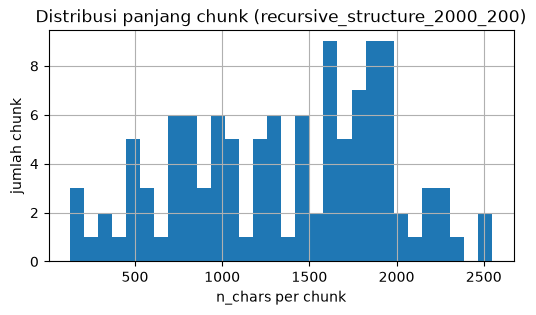

Chunk dengan section_heading terisi: 112/114 (98%)
Chunk tabel (is_table=True): 50/114
  n_chars tabel -- min: 126, max: 2550, rata-rata: 1248


In [5]:
import matplotlib.pyplot as plt

n_chars_series = pd.Series([r["n_chars"] for r in all_records])
print(n_chars_series.describe())

fig, ax = plt.subplots(figsize=(6, 3))
n_chars_series.hist(bins=30, ax=ax)
ax.set_xlabel("n_chars per chunk")
ax.set_ylabel("jumlah chunk")
ax.set_title(f"Distribusi panjang chunk ({chunk_strategy})")
plt.show()

n_with_heading = sum(1 for r in all_records if r["section_heading"])
print(f"Chunk dengan section_heading terisi: {n_with_heading}/{len(all_records)} "
      f"({n_with_heading / len(all_records):.0%})")

n_table_chunks = sum(1 for r in all_records if r["is_table"])
print(f"Chunk tabel (is_table=True): {n_table_chunks}/{len(all_records)}")
if n_table_chunks:
    table_n_chars = pd.Series([r["n_chars"] for r in all_records if r["is_table"]])
    print(f"  n_chars tabel -- min: {table_n_chars.min()}, max: {table_n_chars.max()}, rata-rata: {table_n_chars.mean():.0f}")


## Inspeksi manual: 3 chunk acak

Periksa apakah `section_heading` masuk akal dan teks tidak terpotong aneh —
ini pengecekan mata terhadap heuristik heading/paragraf di `src/chunking.py`.

In [6]:
for r in random.sample(all_records, k=3):
    print(f"chunk_id: {r['chunk_id']}")
    print(f"halaman: {r['page_start']}-{r['page_end']}  |  section_heading: {r['section_heading']!r}")
    print(f"n_chars: {r['n_chars']}  n_tokens(est): {r['n_tokens']}")
    print(r["text"][:400])
    print("-" * 80)

chunk_id: lpmb-2026-panduan-usulan-pengmas-internal-universitas-airlan::p67::c001
halaman: 67-67  |  section_heading: '18. Lain-lain'
n_chars: 2212  n_tokens(est): 553
| Transaksi luaran pada proposal |  |  |  |  |  |  |  | Validasi/penilaian luaran |  |  |  |  |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
|  | Kategori |  | Jenis | Status | Bukti Luaran |  | Target |  | Kriteria | Isian Peneliti | Bukti Pendukung | Tidak Valid |
|  | Luaran |  | Luaran |  |  |  | Capaian |  | Kelayakan |  |  |  |
|  |  |  |  |  |  |  |  |  | 
--------------------------------------------------------------------------------
chunk_id: lpmb-2026-panduan-usulan-pengmas-internal-universitas-airlan::p17::c001
halaman: 17-18  |  section_heading: '6. Tahap Pelaksanaan'
n_chars: 993  n_tokens(est): 248
dan Rencana Anggaran Biaya (RAB). b. Penandatanganan kontrak pengabdian kepada masyarakat. c. Pencairan dana pengabdian kepada masyarakat. d. Pelaksanaan kegiatan sesuai dengan

## Inspeksi manual: chunk tabel

Verifikasi bahwa tabel (mis. Tabel 2.3 di halaman 22, yang sebelumnya hancur oleh `extract_text()` — nilai pendanaan/skema/jumlah anggota terinterleaving acak lintas kolom) sekarang menjadi satu chunk Markdown utuh dengan tiap baris tabel tetap koheren.

In [7]:
table_chunks = [r for r in all_records if r["is_table"]]
print(f"Total chunk tabel: {len(table_chunks)}")

sample_table = next((r for r in table_chunks if r["page_start"] == 22), table_chunks[0])
print(f"chunk_id: {sample_table['chunk_id']}")
print(f"halaman: {sample_table['page_start']}-{sample_table['page_end']}  n_chars: {sample_table['n_chars']}")
print(sample_table["text"])

Total chunk tabel: 50
chunk_id: lpmb-2026-panduan-usulan-pengmas-internal-universitas-airlan::p22::c001
halaman: 22-22  n_chars: 1025
Tabel 2.2. Tahapan Pengusulan dan Jadwal Internal Universitas Airlangga Tahun 2026 Tabel 2.3. Skema, Tim Pelaksana, Waktu, dan Pendanaan

| No |  | Kegiatan |  | Waktu |
| --- | --- | --- | --- | --- |
| 1. | Sosialisasi dan Launching |  | 21 Mei 2026 |  |
| 2. | Pengumuman dan Pengajuan proposal |  | 26 Mei - 5 Juni 2026 |  |
| 3. | Penilaian Proposal Pengabdian kepada masyarakat |  | 12 - 19 Juni 2026 |  |
| 4. | Penetapan Fakultas |  | 24 - 26 Juni 2026 |  |
| 5. | Pengumuman Proposal Didanai |  | 1 Juli 2026 |  |
| 6. | Kontrak Pengabdian |  | 1 Juli 2026 |  |
| 7. | Pelaksanaan Pengabdian kepada masyarakat |  | Juli - Desember 2026 |  |
| 8. | Unggah Laporan kemajuan |  | 1 - 4 September 2026 |  |
| 9. | Monev Internal |  | 9-11 September 2026 |  |
| 10. | Monev Lapangan Pengmas |  | 17 September – 29 Nopember ; 2026 |  |
| 11. | Unggah Laporan Akhi

## ASSERT

In [8]:
assert len(all_records) > 0, "Tidak ada chunk dihasilkan"

chunk_ids = [r["chunk_id"] for r in all_records]
assert len(chunk_ids) == len(set(chunk_ids)), "chunk_id tidak unik lintas dokumen"

for r in all_records:
    assert r["page_start"] <= r["page_end"], f"page_start > page_end: {r['chunk_id']}"
    assert r["text"].strip(), f"teks kosong: {r['chunk_id']}"
    if not r["is_table"]:
        # Chunk tabel SENGAJA dikecualikan dari kedua batas ini -- satu
        # tabel = satu chunk utuh, berapa pun ukurannya (lihat
        # src/chunking.py::build_chunk_records dan README).
        assert r["n_chars"] >= cfg.chunking.min_chunk_chars, (
            f"n_chars di bawah batas pada chunk non-tabel: {r['chunk_id']} -> {r['n_chars']}"
        )
        # Batas atas soft_max (bukan chunk_size): paragraf tunggal sepanjang
        # (chunk_size, soft_max] sengaja dibiarkan jadi satu chunk sendiri
        # tanpa dipaksa lewat recursive_chunk (lihat README, rekomendasi
        # soft_max/toleransi luapan 1.3x).
        assert r["n_chars"] <= cfg.chunking.soft_max, (
            f"n_chars melebihi soft_max pada chunk non-tabel: {r['chunk_id']} -> {r['n_chars']}"
        )
    assert r["chunk_strategy"] == chunk_strategy, f"chunk_strategy tidak konsisten: {r['chunk_id']}"

print("Semua assert lolos.")

Semua assert lolos.


## Tulis `chunks.jsonl`

In [9]:
out_path = "../data/processed/chunks.jsonl"
chunking.write_chunks_jsonl(all_records, out_path)
print(f"Ditulis {len(all_records)} chunk ke {out_path}")

Ditulis 114 chunk ke ../data/processed/chunks.jsonl


## Ringkasan

In [10]:
total_dropped = sum(s["n_dropped_short"] for s in per_doc_stats)
total_dropped_dot_noise = sum(s["n_dropped_dot_noise"] for s in per_doc_stats)
total_merged_orphan = sum(s["n_merged_orphan"] for s in per_doc_stats)
print(f"Dokumen diproses: {len(documents)} (dilewati: {len(skipped_not_extractable)})")
print(f"Total chunk: {len(all_records)}")
print(f"Total dibuang (< {cfg.chunking.min_chunk_chars} karakter): {total_dropped}")
print(f"Total dibuang (rasio titik > {cfg.chunking.max_dot_ratio}, mis. daftar isi): {total_dropped_dot_noise}")
print(f"Total chunk yatim dilebur ke tetangga (bukan dibuang): {total_merged_orphan}")
print(f"Rata-rata n_chars: {n_chars_series.mean():.0f}")
print(f"Chunk dengan section_heading: {n_with_heading}/{len(all_records)} ({n_with_heading / len(all_records):.0%})")
print(f"Chunk tabel: {n_table_chunks}/{len(all_records)}")
print(f"chunk_strategy: {chunk_strategy}")

Dokumen diproses: 1 (dilewati: 0)
Total chunk: 114
Total dibuang (< 250 karakter): 0
Total dibuang (rasio titik > 0.2, mis. daftar isi): 6
Total chunk yatim dilebur ke tetangga (bukan dibuang): 15
Rata-rata n_chars: 1355
Chunk dengan section_heading: 112/114 (98%)
Chunk tabel: 50/114
chunk_strategy: recursive_structure_2000_200
